# 01 · Exploring the data

Before training anything: what do the feature vectors look like, are the classes balanced,
and do the features need preprocessing? Everything here uses the **training** files only.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.common import *
from src.plotting import *
set_seed()

data = {t: load_task(t) for t in ("image", "sentiment")}
for t, (X, y, Xt, ids) in data.items():
    print(f"{t:9s} train {X.shape}  test {Xt.shape}  classes {len(np.unique(y))}  "
          f"samples/class min {np.bincount(y).min()} max {np.bincount(y).max()}  NaNs {np.isnan(X).sum()}")

image     train (20000, 500)  test (5000, 500)  classes 50  samples/class min 400 max 400  NaNs 0
sentiment train (12000, 768)  test (5000, 768)  classes 3  samples/class min 4000 max 4000  NaNs 0


Both training sets are **perfectly balanced** (400 per image class, 4,000 per sentiment class),
so plain accuracy is a fair metric and a random guess would score 2% (image) and 33% (sentiment).

## Image features: what are they?

In [2]:
X, y, _, _ = data["image"]
nnz = (X > 0).sum(1)
print("min value:", X.min(), "| fraction of exact zeros: %.1f%%" % (100 * (X == 0).mean()))
print("row lengths (L2 norm): mean %.4f, std %.4f" % (np.linalg.norm(X, axis=1).mean(), np.linalg.norm(X, axis=1).std()))
print("non-zero features per image: min %d, median %d, max %d" % (nnz.min(), np.median(nnz), nnz.max()))
# Are the non-zero values multiples of each other? (=> scaled integer counts)
ratios = [r[r > 0] / r[r > 0].min() for r in X[:200]]
print("non-zero values that are whole multiples of the row's smallest value: %.1f%%"
      % (100 * np.mean(np.concatenate([np.abs(q - np.round(q)) < 1e-3 for q in ratios]))))
print("example row, non-zero values / smallest:", np.round(np.sort(ratios[0])[::-1][:12], 2))

min value: 0.0 | fraction of exact zeros: 85.2%
row lengths (L2 norm): mean 1.0000, std 0.0000
non-zero features per image: min 4, median 61, max 201
non-zero values that are whole multiples of the row's smallest value: 100.0%
example row, non-zero values / smallest: [4. 2. 2. 2. 2. 1. 1. 1. 1. 1. 1. 1.]


**Interpretation.** Every image vector is non-negative, ~85% zeros, has length exactly 1, and its
non-zero entries are whole-number multiples of each other. That is the signature of a
**bag-of-visual-words histogram**: the extractor found local patches in the image, matched each
to one of 500 "visual words", counted them, and divided by the vector's length.

Consequences we test later:
* Euclidean and cosine distance give *identical* k-NN neighbours on the raw data (all vectors have length 1).
* The **Hellinger transform** (divide by the total count, take the square root) is the classic
  preprocessing for histograms: it stops a few very frequent visual words from dominating distances.
* Single features are weak evidence (one visual word present or absent), which is bad news for
  decision trees, which split on one feature at a time.

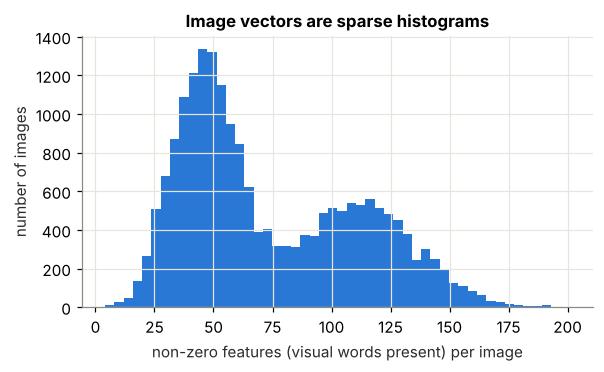

In [3]:
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.hist(nnz, bins=50, color=PALETTE[0])
ax.set_xlabel("non-zero features (visual words present) per image")
ax.set_ylabel("number of images")
ax.set_title("Image vectors are sparse histograms")
savefig(fig, "01_image_sparsity"); plt.show()

## Sentiment features (BERT mean-pooled embeddings)

In [4]:
X, y, _, _ = data["sentiment"]
m, s = X.mean(0), X.std(0)
print("value range: [%.2f, %.2f]" % (X.min(), X.max()))
print("per-feature mean ranges from %.2f to %.2f, std from %.2f to %.2f" % (m.min(), m.max(), s.min(), s.max()))
outlier = np.argsort(np.abs(m))[::-1][:3]
print("features with the largest |mean|:", {int(j): round(float(m[j]), 2) for j in outlier})
print("row lengths: mean %.2f, std %.2f" % (np.linalg.norm(X, axis=1).mean(), np.linalg.norm(X, axis=1).std()))

value range: [-5.07, 1.75]
per-feature mean ranges from -3.48 to 0.85, std from 0.15 to 0.63
features with the largest |mean|: {308: -3.48, 180: -0.88, 123: 0.85}
row lengths: mean 8.94, std 0.49


Dense, real-valued features. A handful of dimensions have large offsets (one has mean ≈ −3.5, a
known quirk of BERT's hidden states). Without **standardising**, those few dimensions dominate
Euclidean distances, so standardisation is likely to matter for k-NN and the neural network
(trees don't care: a split threshold works the same on any monotonic rescaling of a feature).

## How separable are the classes? A 2-D PCA view

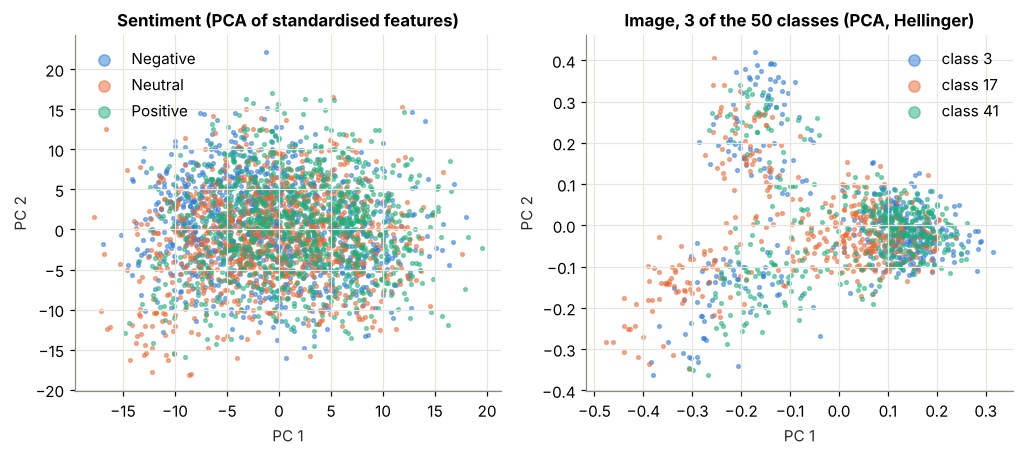

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
# Sentiment: standardise, project on the top-2 principal components
Xs, ys, _, _ = data["sentiment"]
pp = Preprocessor("standardize", pca_dims=2).fit(Xs)
Z = pp.transform(Xs)
rng = np.random.default_rng(SEED)
sub = rng.choice(len(Z), 3000, replace=False)
for c, name in enumerate(SENTIMENT_NAMES):
    pts = sub[ys[sub] == c]
    axes[0].scatter(Z[pts, 0], Z[pts, 1], s=6, alpha=0.5, color=PALETTE[c], label=name)
axes[0].set_title("Sentiment (PCA of standardised features)")
axes[0].legend(markerscale=3)
axes[0].set_xlabel("PC 1"); axes[0].set_ylabel("PC 2")

# Image: Hellinger transform, 3 random classes only (50 would be unreadable)
Xi, yi, _, _ = data["image"]
pp_i = Preprocessor("hellinger", pca_dims=2).fit(Xi)
Zi = pp_i.transform(Xi)
for j, c in enumerate([3, 17, 41]):
    pts = np.flatnonzero(yi == c)
    axes[1].scatter(Zi[pts, 0], Zi[pts, 1], s=6, alpha=0.5, color=PALETTE[j], label=f"class {c}")
axes[1].set_title("Image, 3 of the 50 classes (PCA, Hellinger)")
axes[1].legend(markerscale=3)
axes[1].set_xlabel("PC 1"); axes[1].set_ylabel("PC 2")
savefig(fig, "01_pca_scatter"); plt.show()

**Neither view separates the classes.** For sentiment, the two directions along which tweets
differ the most say nothing about sentiment: they capture other variation (topic,
wording, length…), and all three classes sit on top of each other. For images, the PCA view does
show groups (blobs), but each blob contains all three classes, so the strongest structure in
the histograms is something other than object identity. Whatever separates the classes lives in
less dominant directions, spread across many dimensions. That is exactly why we need classifiers.

A direction chosen *using the labels* tells a different story. Below we project every tweet onto
the line joining the average Negative tweet to the average Positive tweet (computed on the
training split only).

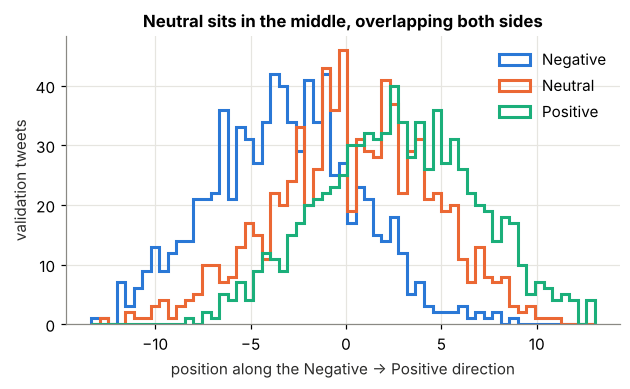

Negative mean position  -3.26   std 3.82
Neutral  mean position   0.35   std 4.11
Positive mean position   2.73   std 4.05


In [6]:
Xtr_s, ytr_s, Xva_s, yva_s = get_split("sentiment")
pp = Preprocessor("standardize").fit(Xtr_s)
A, B = pp.transform(Xtr_s), pp.transform(Xva_s)
direction = A[ytr_s == 2].mean(0) - A[ytr_s == 0].mean(0)
direction /= np.linalg.norm(direction)
proj = B @ direction                      # validation tweets, projected
fig, ax = plt.subplots(figsize=(6.5, 3.4))
bins = np.linspace(proj.min(), proj.max(), 60)
for c, name in enumerate(SENTIMENT_NAMES):
    ax.hist(proj[yva_s == c], bins=bins, histtype="step", linewidth=2, color=PALETTE[c], label=name)
ax.set_xlabel("position along the Negative → Positive direction")
ax.set_ylabel("validation tweets")
ax.set_title("Neutral sits in the middle, overlapping both sides")
ax.legend()
savefig(fig, "01_sentiment_projection"); plt.show()
for c, name in enumerate(SENTIMENT_NAMES):
    print(f"{name:8s} mean position {proj[yva_s == c].mean():6.2f}   std {proj[yva_s == c].std():.2f}")

Along this single direction, Negative and Positive tweets shift to opposite sides (average
positions about −3.3 and +2.7) but still overlap a lot (spread ≈ 4 for each class). Neutral tweets
sit in the middle and overlap both. Expect **Neutral to be the hardest class**, and expect no
model to get close to 100%: many tweets simply look alike in this representation.

image: components for 50% / 90% of variance = 133 / 382


sentiment: components for 50% / 90% of variance = 32 / 247


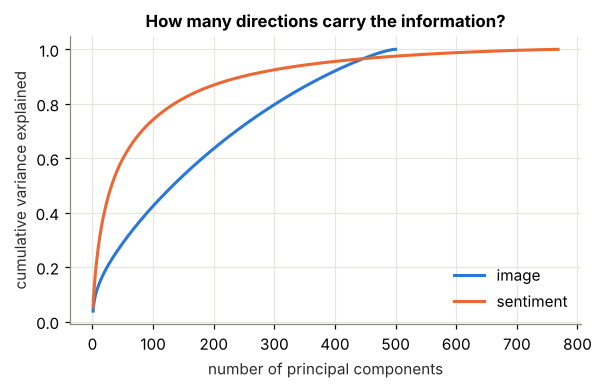

In [7]:
fig, ax = plt.subplots(figsize=(6, 3.4))
for j, (t, mode) in enumerate([("image", "hellinger"), ("sentiment", "standardize")]):
    X = data[t][0]
    pp = Preprocessor(mode, pca_dims=X.shape[1]).fit(X)
    cum = np.cumsum(pp.explained_var_ratio_)
    ax.plot(np.arange(1, len(cum) + 1), cum, color=PALETTE[j], label=t)
    print(f"{t}: components for 50% / 90% of variance = {np.searchsorted(cum, .5) + 1} / {np.searchsorted(cum, .9) + 1}")
ax.set_xlabel("number of principal components"); ax.set_ylabel("cumulative variance explained")
ax.set_title("How many directions carry the information?")
ax.legend()
savefig(fig, "01_pca_variance"); plt.show()

The image features need far more directions to describe them than the sentiment features do.
The sentiment embeddings are highly correlated (a few hundred directions explain most of the
variance); the image histograms are spread over most of their 500 dimensions.